In [3]:
import networkx as nx
from scipy.io import mmread
import pickle

#Data Import
#G = nx.from_scipy_sparse_array(mmread("socfb-Cornell5/socfb-Cornell5.mtx"))
G = pickle.load(open('processed/G.pkl', 'rb'))  # reply network, built by sample_graph.py
authors_per_sub = pickle.load(open('processed/authors_per_sub.pkl', 'rb'))#Load sub-reddit sizes based upon sampled authors

In [4]:
#Simple Network Stats
import numpy as np
N= G.number_of_nodes()
L= G.number_of_edges()
deg = dict(G.degree())
cc = list(dict(nx.clustering(G)).values())

k_avg= np.mean(list(deg.values()))
average_clustering = np.mean(cc)

print("N: ", N)
print("L: ", L)
print("Average Degree: ", k_avg)
print("Average Clustering: ", average_clustering)


G_null = G.copy() #Config Null Model: w/ no self-loops or multi-path
nx.double_edge_swap(G_null, nswap=10 * G_null.number_of_edges(),
                    max_tries=100 * G_null.number_of_edges(), seed=42)

N_null= G_null.number_of_nodes()
L_null= G_null.number_of_edges()
deg_null = dict(G_null.degree())
cc_null = list(dict(nx.clustering(G_null)).values())

k_avg_null= np.mean(list(deg_null.values()))
average_clustering_null = np.mean(cc_null)

print("N_null: ", N_null)
print("L_null: ", L_null)
print("Average Degree (Null Model): ", k_avg_null)
print("Average Clustering (Null Model): ", average_clustering_null)

N:  7023
L:  58547
Average Degree:  16.672931795528978
Average Clustering:  0.06463024080960647
N_null:  7023
L_null:  58547
Average Degree (Null Model):  16.672931795528978
Average Clustering (Null Model):  0.020769286570820812


In [5]:
#Creating a list of null models
list_of_nulls = []
for i in range(1,100):
    null_entry = G.copy()
    nx.double_edge_swap(null_entry, nswap=2*G_null.number_of_edges(),
                    max_tries=4 * G_null.number_of_edges())
    list_of_nulls.append(null_entry)

In [6]:
#Generating Stats based upon many Null Models
N_nulls= []
L_nulls=[]
deg_nulls=[]
cc_nulls=[]
for null in list_of_nulls:
    N_nulls.append(null.number_of_nodes())
    L_nulls.append(null.number_of_edges())
    deg_nulls.append(dict(null.degree()))
    cc_nulls.append(list(dict(nx.clustering(null)).values()))


In [7]:
from itertools import chain

k_avg_null= np.mean(list(chain.from_iterable(item.values() for item in deg_nulls)))#'*' is used to go in one level
average_clustering_null = np.mean(cc_nulls)

print("N_nulls: ", np.mean(N_nulls))
print("L_nulls: ", np.mean(L_nulls))
print("Average Degree (Null Models): ", k_avg_null)
print("Average Clustering (Null Models): ", average_clustering_null)

N_nulls:  7023.0
L_nulls:  58547.0
Average Degree (Null Models):  16.672931795528978
Average Clustering (Null Models):  0.02046306273700804


Super interesting result! The average degree is about the same as the configuration model! This suggests that people are about as much as random.
But! The clustering is incredibly high on reddit. Far higher than random. 

This tells me that Reddit connects people as much as we would expect for its structure.
A follow-up question though is: is this also what we expect offline?

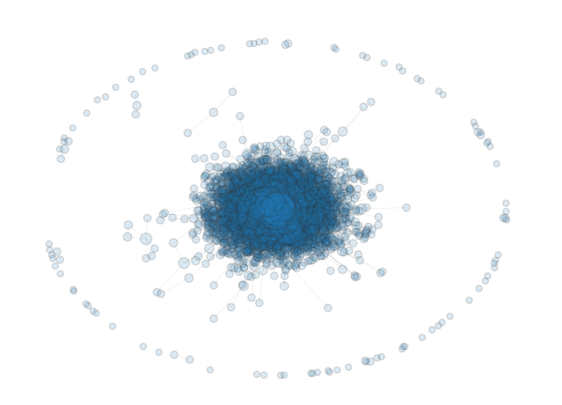

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1,figsize=(7,5),dpi=100)

pos = nx.spring_layout(G, scale=20, k=3/np.sqrt(G.order()))
sizes = [20 + 8 * G.degree(n) for n in G.nodes]

nx.draw(G, pos, node_size=sizes, alpha=0.15, width=0.5, edgecolors='.2',
        with_labels=False, font_size='x-small', edge_color='.6',ax=ax)

Here we can see the graph constructed, where nodes are sized by degree (larger is bigger). Here, each node reflects a comment, and size effectively shows us the comments on the posts with the most amount of comments (i.e., highest number of potential connections)

In [ ]:
#Community Detection
import networkx as nx
import numpy as np
from collections import defaultdict
from random import shuffle
import matplotlib.pyplot as plt
import community

partition = community.best_partition(G)#Louvain

# Output the best modularity score
print("Best Modularity: ", community.modularity(partition, G))

# Output the Number of Communities Detected {node_id: community_id}
print("Number of Communities Detected: ",len(np.unique(list(partition.values()))))

# Storing and showing partition as dictionary
G_parts = dict(partition)
print("Partition Dictionary: ", G_parts)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(partition.values())))))
colors_nodes = [colors_sns[partition[node]] for node in G.nodes()]

#Repeating analysis for all nulls
partition_nulls=[]
modularity_scores=[]
number_of_communities=[]
for null in list_of_nulls:
    partition_null = community.best_partition(null)
    partition_nulls.append(partition_null)#Louvain
    modularity_scores.append(community.modularity(partition_null, null))
    number_of_communities.append(len(np.unique(list(partition_null.values()))))

# Output the average modularity score across the null models
print("Modularity (Null Models, mean ± std): ", np.mean(modularity_scores), "±", np.std(modularity_scores))

# Output the Number of Communities Detected {node_id: community_id}
print("Number of Communities Detected (Null Model): ", np.mean(number_of_communities))

# Output the Number of Subreddits Actual {node_id: community_id}
print("Number of Actual Subreddit Communities Sampled: ", len(list(authors_per_sub.values())))


# Taking just 1 Null to Store and show partition as dictionary
partition_null =community.best_partition(G_null)
G_parts_null = dict(partition_null)
print("Partition Dictionary (Null Model): ", G_parts_null)
colors_sns_null = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(partition_null.values())))))
colors_nodes_null = [colors_sns_null[partition_null[node]] for node in G_null.nodes()]

Particularly high modularity from Louvain. While exciting, unclear whether this is an artifact of how I constructed the graph (i.e., via comments connected to posts. I may be inflating posts with comments as oppossed to those without.) Similarly, I wonder how much of this is simply explained by the post, or subreddit id. Is that how comments are being community organized? We can see from the sub-reddit data that there are actually 3258 number of sub-reddits that were sampled, which is fair more than the results obtained from the Louvain, and not to mention the Configuration Null Model. This suggests that there are significant cross-communities amongst sub-reddits which is expected, though it also implies Louvain may be hitting a resolution limit that is causing a siginificant difference in the data. 

Next, I plan to run NLP of each of the reddit comments to identify potential depressed users, and then re-evaluate the Louvain based on these two kinds of users I break up the sample into.

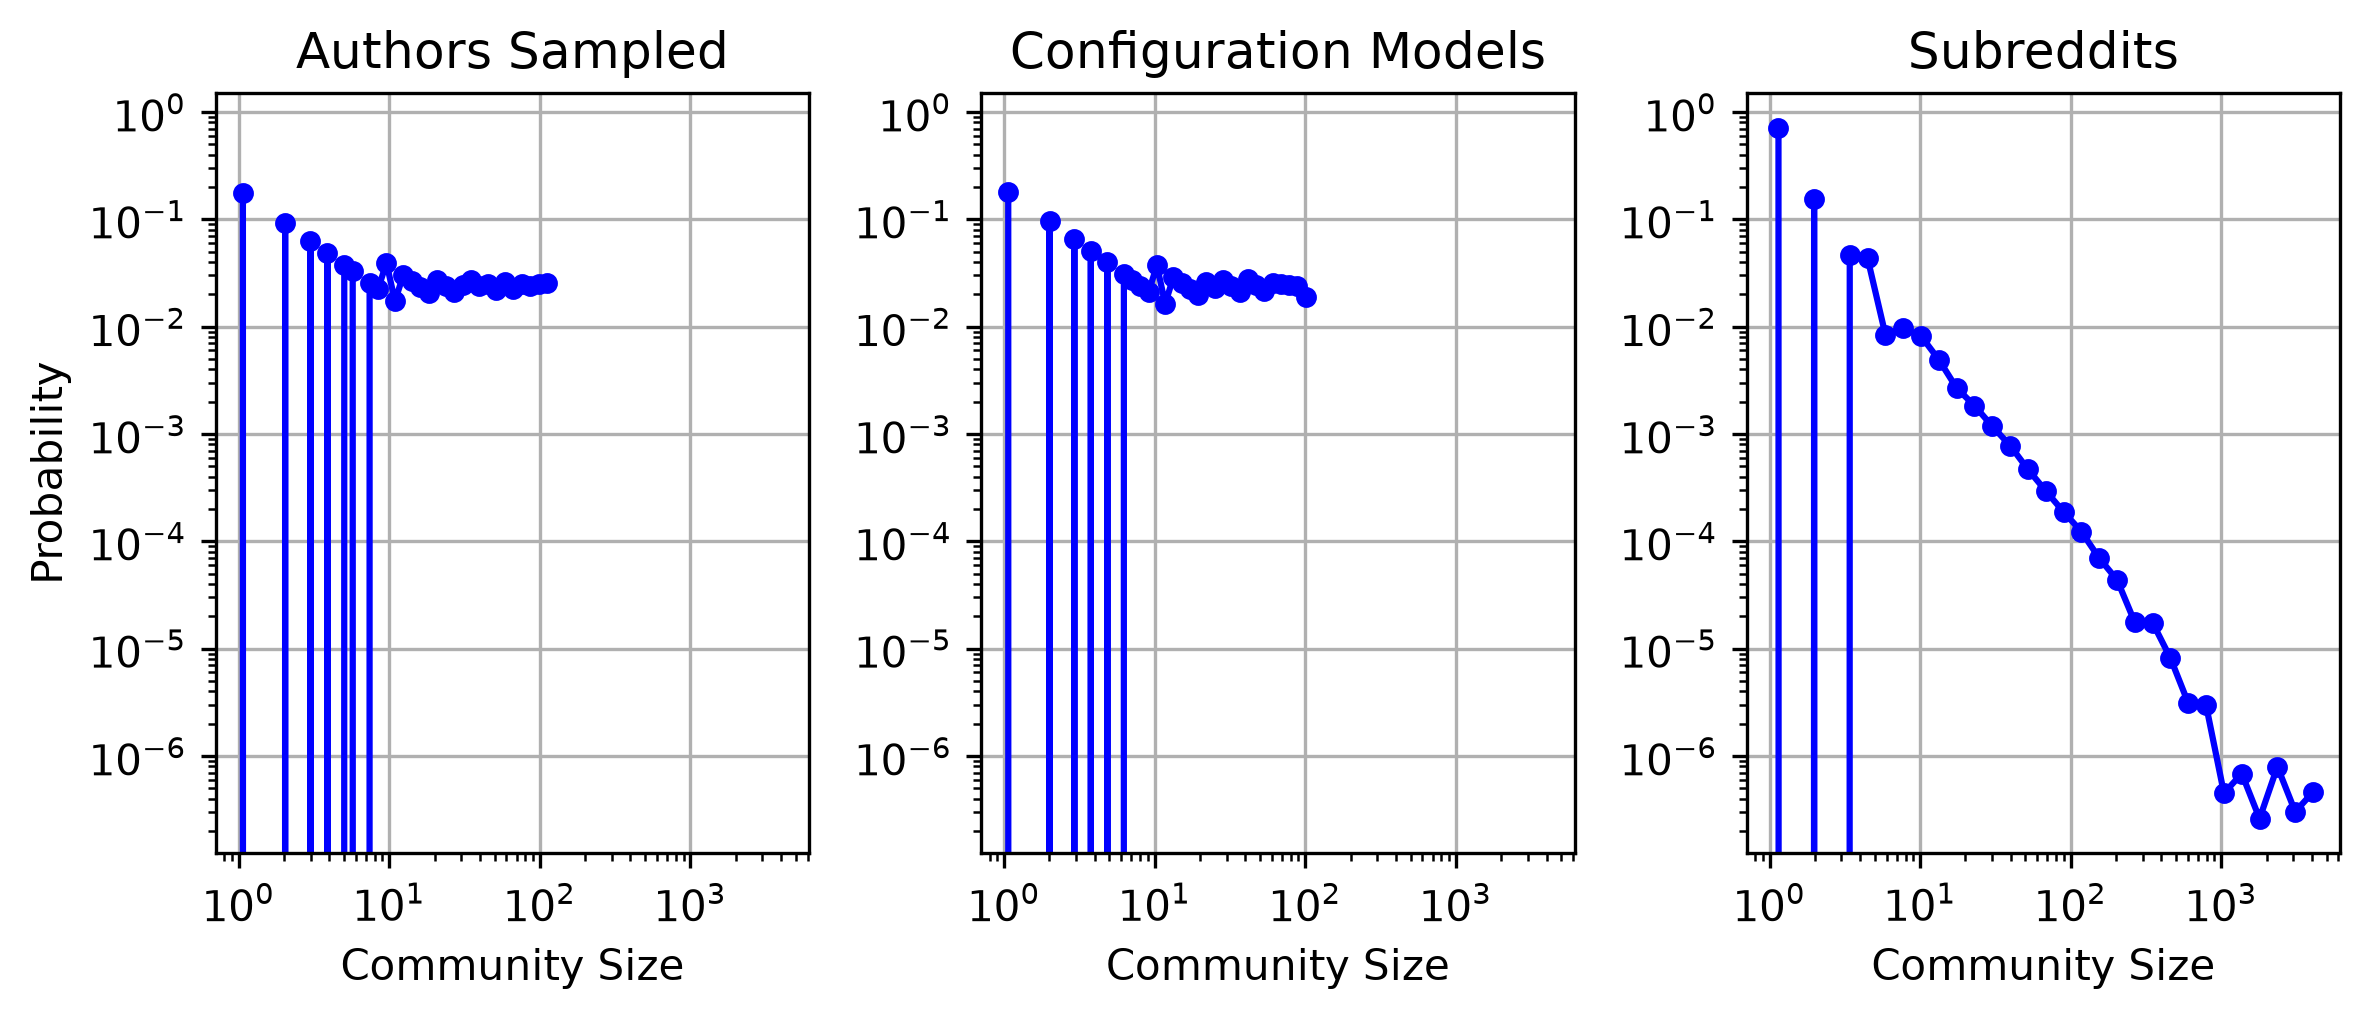

In [53]:
from collections import Counter
import itertools

community_sizes = Counter(G_parts.values())
null_community_sizes = []
for G_parts_null in partition_nulls:
    null_community_sizes.append(list(Counter(dict(G_parts_null).values())))

null_community_sizes= list(itertools.chain(*null_community_sizes)) #Unpack list of lists to single list
fig, ax = plt.subplots(1,3,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)

# Plotting the community size distribution of the original dataset
num=int(2*N**(1/3))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.
org_bins = np.geomspace(1,np.max(list(community_sizes)),num=num)#Defining the smallest community as an isolated node of 1
#ax[0].hist(list(community_sizes),bins=org_bins, density=True,color = 'b',histtype='step')
counts_org, bin_edges_org = np.histogram(list(community_sizes), bins=org_bins, density=True)
bin_centers_org = np.sqrt(bin_edges_org[:-1] * bin_edges_org[1:])
ax[0].loglog(bin_centers_org, counts_org/counts_org.sum(), marker='o', ms=4,color = 'b')#Normalize for the number of models sampled
ax[0].loglog()
ax[0].set_title("Authors Sampled")
ax[0].set_xlabel("Community Size")
ax[0].set_ylabel("Probability")
ax[0].grid(True)

# Plotting the community size distribution of the Configuration Null Model of the dataset
null_bins = np.geomspace(1,np.max((null_community_sizes)),num=num)
#ax[1].hist(list(null_community_sizes),bins=null_bins,density=True,color = 'b',histtype='step')
counts_null, bin_edges_null = np.histogram(list(null_community_sizes), bins=null_bins, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax[1].loglog(bin_centers_null, counts_null/counts_null.sum(), marker='o', ms=4,color = 'b')
ax[1].loglog()
ax[1].set_title("Configuration Models")
ax[1].set_xlabel("Community Size")
#ax[1].set_ylabel("Probability")
ax[1].tick_params(labelleft=True)
ax[1].grid(True)

num=int(2*len(list(authors_per_sub.values()))**(1/3))
# Plotting the community size distribution of the Subreddit Null Model of the dataset
sub_bins = np.geomspace(1,np.max(list(authors_per_sub.values())),num=num)
counts_sub, bin_edges_sub = np.histogram(list(authors_per_sub.values()), bins=sub_bins, density=True)
bin_centers_sub = np.sqrt(bin_edges_sub[:-1] * bin_edges_sub[1:])
ax[2].loglog(bin_centers_sub, counts_sub/counts_sub.sum(), marker='o', ms=4,color = 'b')
ax[2].loglog()
ax[2].set_title("Subreddits") #Calculating by summing the total of all sampled Authors who Commented in them at some point/post
ax[2].set_xlabel("Community Size")
ax[2].tick_params(labelleft=True)
ax[2].grid(True)

plt.tight_layout()

Interesting we can see the sampled authors have a seemingly clear power law distribution of community sizes with an exception being that the largest communities are all equally higher than expected probability. This makes sense, we would anticipate that some of the largest communities on reddit that are the most visible, active in and promoted (like, r/all) may manifest in this way. In the configuration model, we see that based upon this network it's much more likely for smaller communities to exist with a very steep drop off after about a community size of ~10-20. In the comparison of the actual subreddits we sampled (by the number of commenters I sampled), we can see an apparent mix of distributions. There's some power-law shapeat the tails, but with seemingly multiple different alpha values that creates a kind-of bow out rather than the bow-in we might expect in a truncated power-law or standard log-normal distribution. This I think, is a kind of reconciliation of the prior two models. The sampled community sizes graph shows those power law distributions with the largest communities being at a different playing field than the smallest, with this manifesting in the subrredit plot as a kind of set of two different power law distributions. The one reflecting the smaller community sizes being more reflectant of the null model!

I hypothesize this may be due to some of the ways I think social dynamics may play out differently depending on the scale of social circumstances examined. We can think of the smaller communities here as our standard friendship circles or "hangouts" where pretty much every user may know each other. Then we hit the medium circles where this might reflect a kind of classroom or school setting, where people may have heard of one another but don't know every other person in the circle. And lastly, the largest communities which as they approach 1000s of people, are more city-level town-square dynamics. 

In this hypothetical, the first sampled plot starts to make a lot of sense. There may exist person to person variation where someone's exact social circle size may lie somewhere between ~1-12 people or so, but then there are larger groups users on Reddit tend to join separate from said "friendship circle", of which may fill the purpose of a hobby, school sports team, or interest this user is a part of. And, thus, any given user may pick one of these medium-size communities at equal rate due to external factors (e.g., personal preferences, where say a DnD group just happens to be not as a large as say a full football team group, but serve similar needs (and therefore compete against each other for time) for any given user.

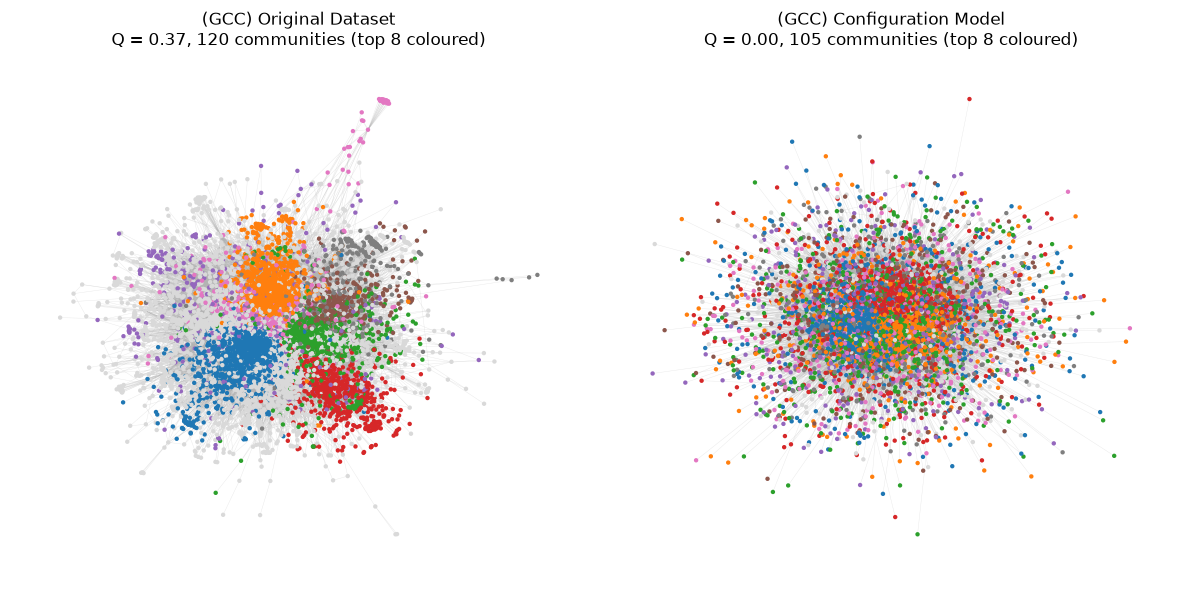

In [107]:
#Community Visualization
from collections import Counter

top_k = 8 # number of largest communities to give their own colour
palette = plt.cm.tab10(np.arange(top_k))
grey = (0.85, 0.85, 0.85, 1.0)

def community_color(comm, biggest):
    # Colour for a community: its own colour if it's one of the biggest, grey otherwise
    if comm in biggest:
        return palette[biggest.index(comm)]
    return grey

def plot_communities(graph, partition, ax, title):
    # Only draw the giant component so the ring of tiny components doesn't clutter the plot
    giant = graph.subgraph(max(nx.connected_components(graph), key=len)).copy()

    # Layout-only weights: edges inside a community pull hard, edges between communities pull weakly.
    # This lets the spring layout separate the communities visually (it doesn't change the graph itself)
    for u, v in giant.edges():
        if partition[u] == partition[v]:
            giant[u][v]['layout_weight'] = 1.0
        else:
            giant[u][v]['layout_weight'] = 0.05
    pos = nx.spring_layout(giant, seed=42, weight='layout_weight', iterations=100) # each graph gets its OWN layout

    biggest = [comm for comm, size in Counter(partition.values()).most_common(top_k)]
    node_colors = [community_color(partition[node], biggest) for node in giant.nodes()]

    nx.draw_networkx_edges(giant, pos, ax=ax, edge_color='.7', width=0.3, alpha=0.3)
    nx.draw_networkx_nodes(giant, pos, ax=ax, node_size=10, node_color=node_colors, linewidths=0)

    Q = community.modularity(partition, graph)
    n_comms = len(set(partition.values()))
    ax.set_title(f"{title}\nQ = {Q:.2f}, {n_comms} communities (top {top_k} coloured)")
    ax.axis('off')

fig, ax = plt.subplots(1,2,figsize=(12,6),dpi=100)
plot_communities(G, partition, ax[0], "(GCC) Original Dataset")
plot_communities(G_null, partition_null, ax[1], "(GCC) Configuration Model")
plt.tight_layout()
plt.show()

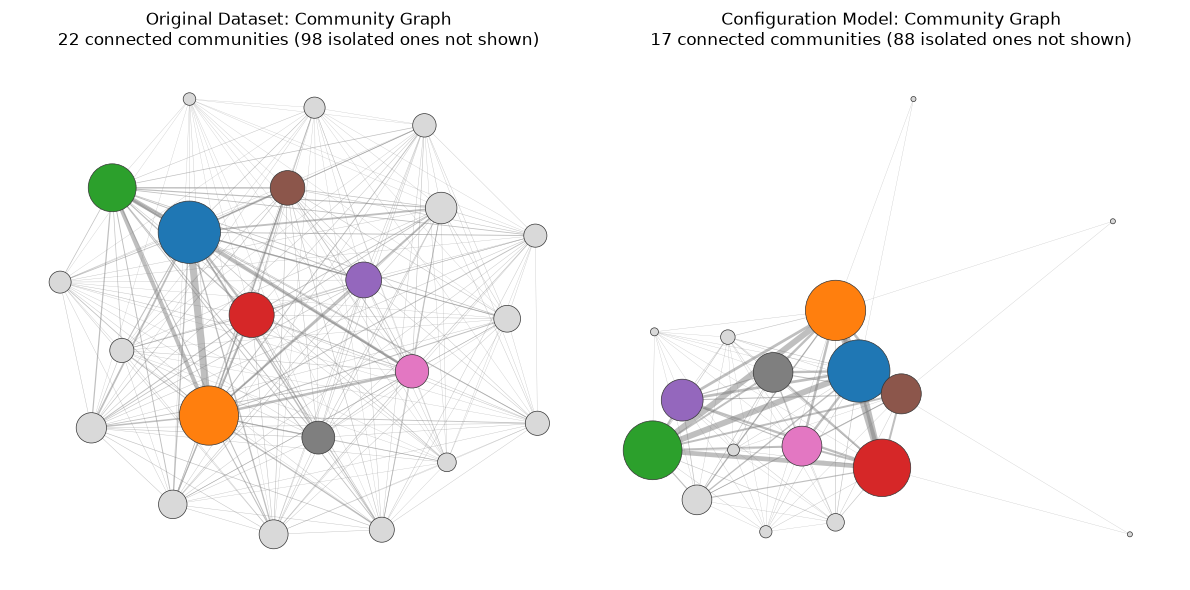

In [102]:
#Coarse-grained view: each community collapsed into a single node
#Node size = number of authors in the community, edge width = number of edges between two communities
fig, ax = plt.subplots(1,2,figsize=(12,6),dpi=100)

graphs_to_plot = [(G, partition, "Original Dataset"),
                  (G_null, partition_null, "Configuration Model")]

for i, (graph, part, title) in enumerate(graphs_to_plot):
    comm_graph = community.induced_graph(part, graph) # python-louvain builds the community graph for us
    comm_graph.remove_edges_from(list(nx.selfloop_edges(comm_graph))) # self-loops = edges inside a community
    isolated = list(nx.isolates(comm_graph)) # communities that are their own separate component
    comm_graph.remove_nodes_from(isolated)

    comm_sizes = Counter(part.values())
    biggest = [comm for comm, size in comm_sizes.most_common(top_k)]
    weights = [comm_graph[u][v]['weight'] for u, v in comm_graph.edges()]

    pos_c = nx.spring_layout(comm_graph, seed=42, weight=None)
    node_sizes = [10 + 2000 * comm_sizes[c] / max(comm_sizes.values()) for c in comm_graph.nodes()]
    node_colors = [community_color(c, biggest) for c in comm_graph.nodes()]
    edge_widths = [0.2 + 5 * w / max(weights) for w in weights]

    nx.draw_networkx_edges(comm_graph, pos_c, ax=ax[i], width=edge_widths, edge_color='.5', alpha=0.5)
    nx.draw_networkx_nodes(comm_graph, pos_c, ax=ax[i], node_size=node_sizes, node_color=node_colors,
                           edgecolors='.2', linewidths=0.5)
    ax[i].set_title(f"{title}: Community Graph\n{comm_graph.number_of_nodes()} connected communities "
                    f"({len(isolated)} isolated ones not shown)")
    ax[i].axis('off')

plt.tight_layout()
plt.show()

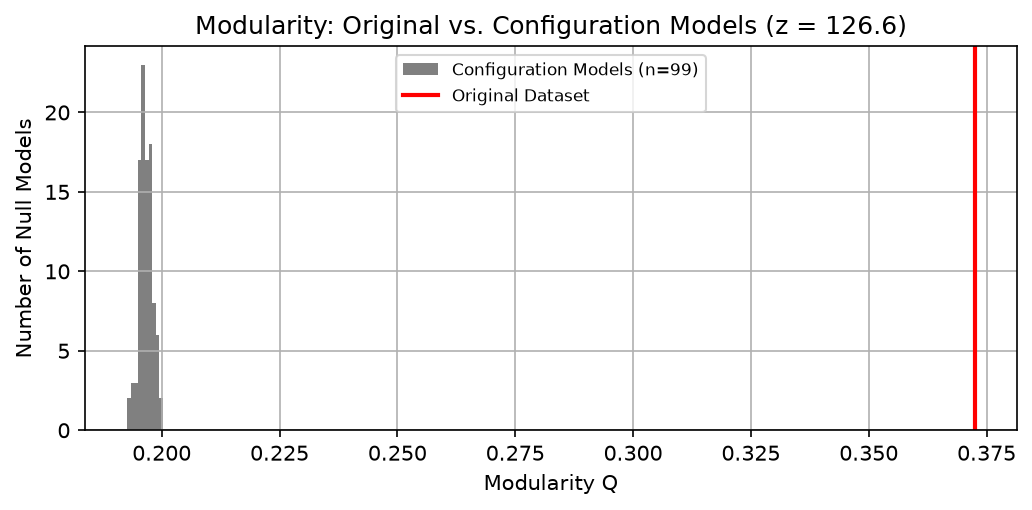

In [103]:
#Modularity significance: where does the real Q fall among the configuration models?
Q_real = community.modularity(partition, G)
z_score = (Q_real - np.mean(modularity_scores)) / np.std(modularity_scores)

fig, ax = plt.subplots(1,1,figsize=(7,3.5),dpi=150)
ax.hist(modularity_scores, bins='auto', color='grey', label=f"Configuration Models (n={len(modularity_scores)})")
ax.axvline(Q_real, color='r', linewidth=2, label="Original Dataset")
ax.set_title(f"Modularity: Original vs. Configuration Models (z = {z_score:.1f})")
ax.set_xlabel("Modularity Q")
ax.set_ylabel("Number of Null Models")
ax.legend(loc="upper center", fontsize="small")
ax.grid(True)
plt.tight_layout()
plt.show()

In [23]:
#Centrality
closeness_centrality = nx.closeness_centrality(G)
betweeness_centrality = nx.betweenness_centrality(G)
degree_centrality = nx.degree_centrality(G)


# Sorting using a for loop
sorted_dict_c = {}
for key in sorted(closeness_centrality, key=closeness_centrality.get, reverse=True):
    sorted_dict_c[key] = closeness_centrality[key]
sorted_dict_b = {}
for key in sorted(betweeness_centrality, key=betweeness_centrality.get, reverse=True):
    sorted_dict_b[key] = betweeness_centrality[key]
sorted_dict_d = {}
for key in sorted(degree_centrality, key=degree_centrality.get, reverse=True):
    sorted_dict_d[key] = degree_centrality[key]

print("Most Central Nodes by Closeness: ", sorted_dict_c)
print("Betweeness Centrality: ", sorted_dict_b)
print("Degree Centrality: ", sorted_dict_d)


Most Central Nodes by Closeness:  {'Lots42': 0.41757862054552014, 'ProbablyHittingOnYou': 0.41213084121194693, 'dummystupid': 0.4100408272864577, 'mepper': 0.4083889280964996, 'maxwellhill': 0.4044010874172602, 'nomdeweb': 0.4031528618254221, '1006_Upside_Down': 0.3990081226161958, 'GhostedAccount': 0.3960301028089146, 'WarPhalange': 0.3931872330191551, 'TheCannon': 0.39293701262209346, 'Warlizard': 0.39289155221686156, 'ZtiWinterfell': 0.3923921811296369, 'aakritiajmera65': 0.3920524280289128, 'feureau': 0.39202979874013766, 'ImNotJesus': 0.39160033805194217, 'Vortilex': 0.3906543347045258, 'webby_mc_webberson': 0.3905195643498669, 'Atario': 0.3903400151248785, 'dirtymoney': 0.38926617739413605, 'XavierMendel': 0.3892438685983658, 'mavriksfan11': 0.38797648024522363, 'C_IsForCookie': 0.3877992613436614, 'Mind_Virus': 0.38768858172115334, 'Radico87': 0.3874453087948024, 'AnnArchist': 0.3870920017766377, 'Phallic': 0.3863873172814248, 'karmadogma': 0.3860359362949236, 'cycophuk': 0.3857

In [ ]:
from collections import defaultdict
#Centrality
closeness_centrality_nulls=[]
#betweeness_centrality_nulls=[]
#degree_centrality_nulls=[]

for null in list_of_nulls: # 'null' (not G_null) so the G_null used in the community plots isn't overwritten
    # Sorting using a for loop
    closeness_centrality_null=nx.closeness_centrality(null)
    '''
    betweeness_centrality_null=nx.betweenness_centrality(null)
    degree_centrality_null=nx.degree_centrality(null)
    sorted_dict_b_null = {}
    for key in sorted(betweeness_centrality_null, key=betweeness_centrality_null.get, reverse=True):
        sorted_dict_b_null[key] = betweeness_centrality_null[key]
    sorted_dict_d_null = {}
    for key in sorted(degree_centrality_null, key=degree_centrality_null.get, reverse=True):
        sorted_dict_d_null[key] = degree_centrality_null[key]
    '''
    sorted_dict_c_null = {}
    for key in sorted(closeness_centrality_null, key=closeness_centrality_null.get, reverse=True):
        sorted_dict_c_null[key] = closeness_centrality_null[key]
    closeness_centrality_nulls.append(closeness_centrality_null)
    #betweeness_centrality_nulls.append(betweeness_centrality_null)
    #degree_centrality_nulls.append(degree_centrality_null)

def average_centrality(list_of_dicts):
    totals = defaultdict(float)
    for d in list_of_dicts:
        for node, val in d.items():
            totals[node] += val
    n = len(list_of_dicts)
    return {node: total / n for node, total in totals.items()}

avg_closeness   = average_centrality(closeness_centrality_nulls)
#avg_betweenness = average_centrality(betweeness_centrality_nulls)
#avg_degree      = average_centrality(degree_centrality_nulls)

# Sorted descending, if you want a ranking
avg_closeness_sorted = dict(sorted(avg_closeness.items(), key=lambda kv: kv[1], reverse=True))
#avg_betweenness_sorted = dict(sorted(avg_betweenness.items(), key=lambda kv: kv[1], reverse=True))
#avg_degree_sorted = dict(sorted(avg_degree.items(), key=lambda kv: kv[1], reverse=True))

print("Most Central Nodes by Average Closeness Across Null Models): ", avg_closeness_sorted)
#print("Betweeness Centrality (Nulls): ", avg_betweenness_sorted)
#print("Degree Centrality (Nulls): ", avg_degree_sorted)


/tmp/ipykernel_124333/2442952380.py:38: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(true_min,true_max)


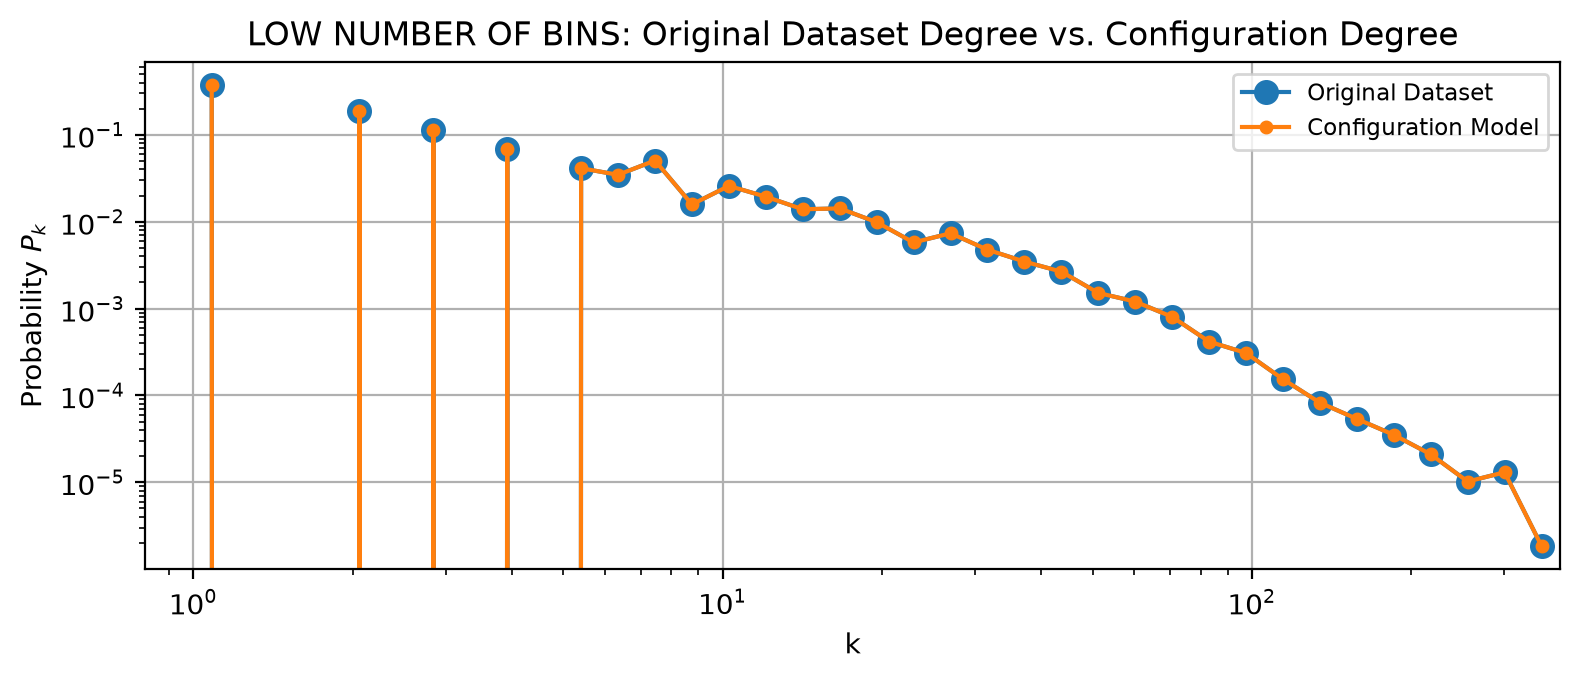

In [54]:
actual_deg_sequence = list(deg.values())
actual_deg_sequence_null = list(deg_null.values())

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

num=int(2*N**(1/3))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.
bins = np.geomspace(1,np.max(actual_deg_sequence),num=num)
counts, bin_edges = np.histogram(actual_deg_sequence, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts/counts.sum(), marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(1,np.max(actual_deg_sequence_null),num=num)
counts_null, bin_edges_null = np.histogram(actual_deg_sequence_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null/counts_null.sum(), marker='o', ms=4, label="Configuration Model")

#LEGACY:
#ax[1].hist(actual_deg_sequence_null,label="Configuration Model Sample",density=True)#Plotting the configuration model graph empirical data
#ax.hist(num_edges_list_chunglu,label="Chung Lu Model Sample",density=True)#Plotting the Chung Lu model graph empirical data
#ax.plot(L,P_l, color = 'r',label="Theoretical Distribution") #Plotting the Theoretical
#handles, labels = ax.get_legend_handles_labels()
#ax[1].legend(handles=handles, labels=labels,loc="upper right",fontsize="small")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("LOW NUMBER OF BINS: Original Dataset Degree vs. Configuration Degree")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_{k}$")
true_min=min(min(actual_deg_sequence), min(actual_deg_sequence_null))
true_max=max(max(actual_deg_sequence), max(actual_deg_sequence_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()


The tail of the degree distribution looked off, relative to a power law. I was curious if my binning was incorrect so I decided to investigate further by increasing the binning:

/tmp/ipykernel_124333/209410663.py:38: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(true_min,true_max)


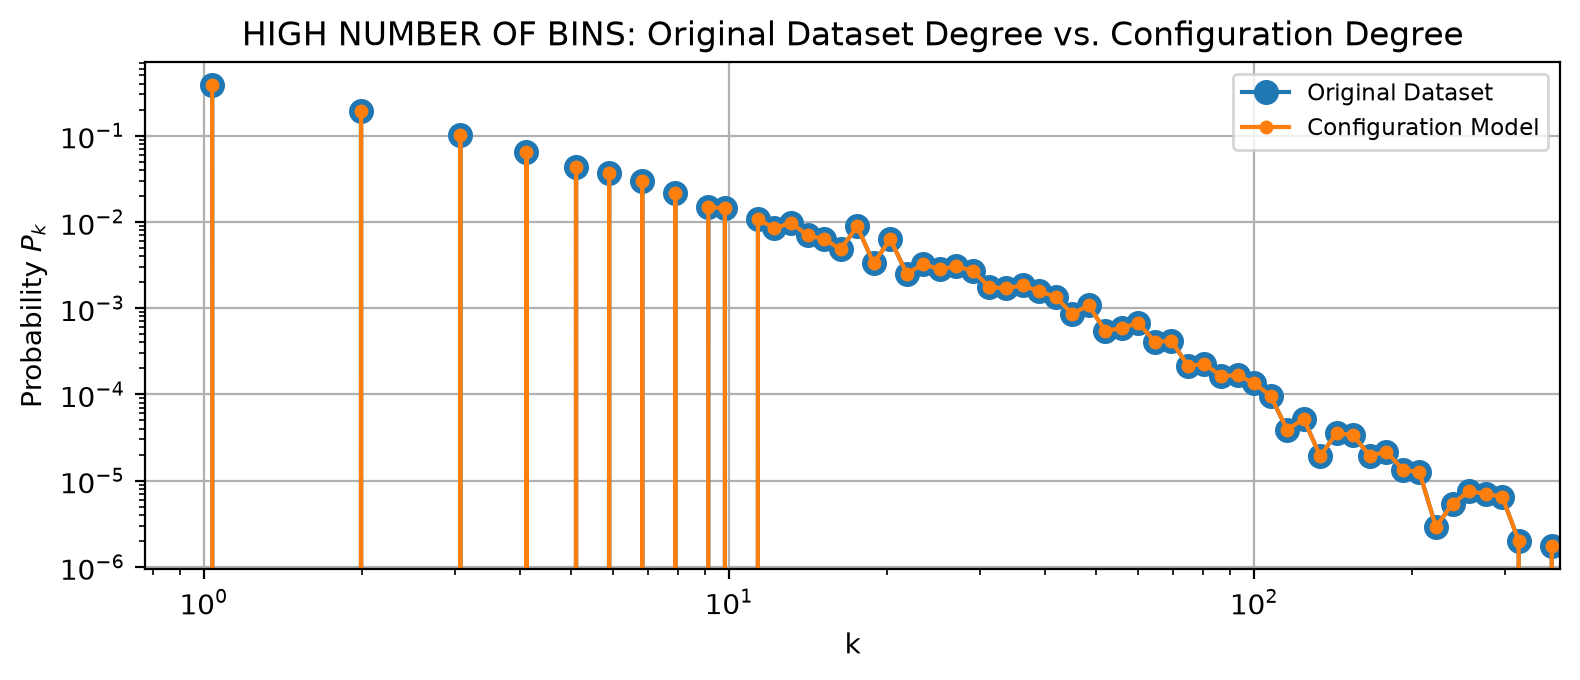

In [55]:
actual_deg_sequence = list(deg.values())
actual_deg_sequence_null = list(deg_null.values())

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

num=int(N**(1/2))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.
bins = np.geomspace(1,np.max(actual_deg_sequence),num=num)
counts, bin_edges = np.histogram(actual_deg_sequence, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts/counts.sum(), marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(1,np.max(actual_deg_sequence_null),num=num)
counts_null, bin_edges_null = np.histogram(actual_deg_sequence_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null/counts_null.sum(), marker='o', ms=4, label="Configuration Model")

#LEGACY:
#ax[1].hist(actual_deg_sequence_null,label="Configuration Model Sample",density=True)#Plotting the configuration model graph empirical data
#ax.hist(num_edges_list_chunglu,label="Chung Lu Model Sample",density=True)#Plotting the Chung Lu model graph empirical data
#ax.plot(L,P_l, color = 'r',label="Theoretical Distribution") #Plotting the Theoretical
#handles, labels = ax.get_legend_handles_labels()
#ax[1].legend(handles=handles, labels=labels,loc="upper right",fontsize="small")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("HIGH NUMBER OF BINS: Original Dataset Degree vs. Configuration Degree")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_{k}$")
true_min=min(min(actual_deg_sequence), min(actual_deg_sequence_null))
true_max=max(max(actual_deg_sequence), max(actual_deg_sequence_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()


Again in the Degree distributions we see that same multi-distribution play out again. Though here the medium and low degree nodes appear much more coalesced. There remains a bit of a change in slope around k=~10 but it definitely is not as large as apparent as it was in the community sizes. This could suggest that users themselves tend to block out into 2  general classes of users.

Is this because there's a group of users that are only active on r/all? It's interesting however that there's such a distinct 2nd power law.

What sub-reddits and posts does the latter curve relate to vs. the former curve?

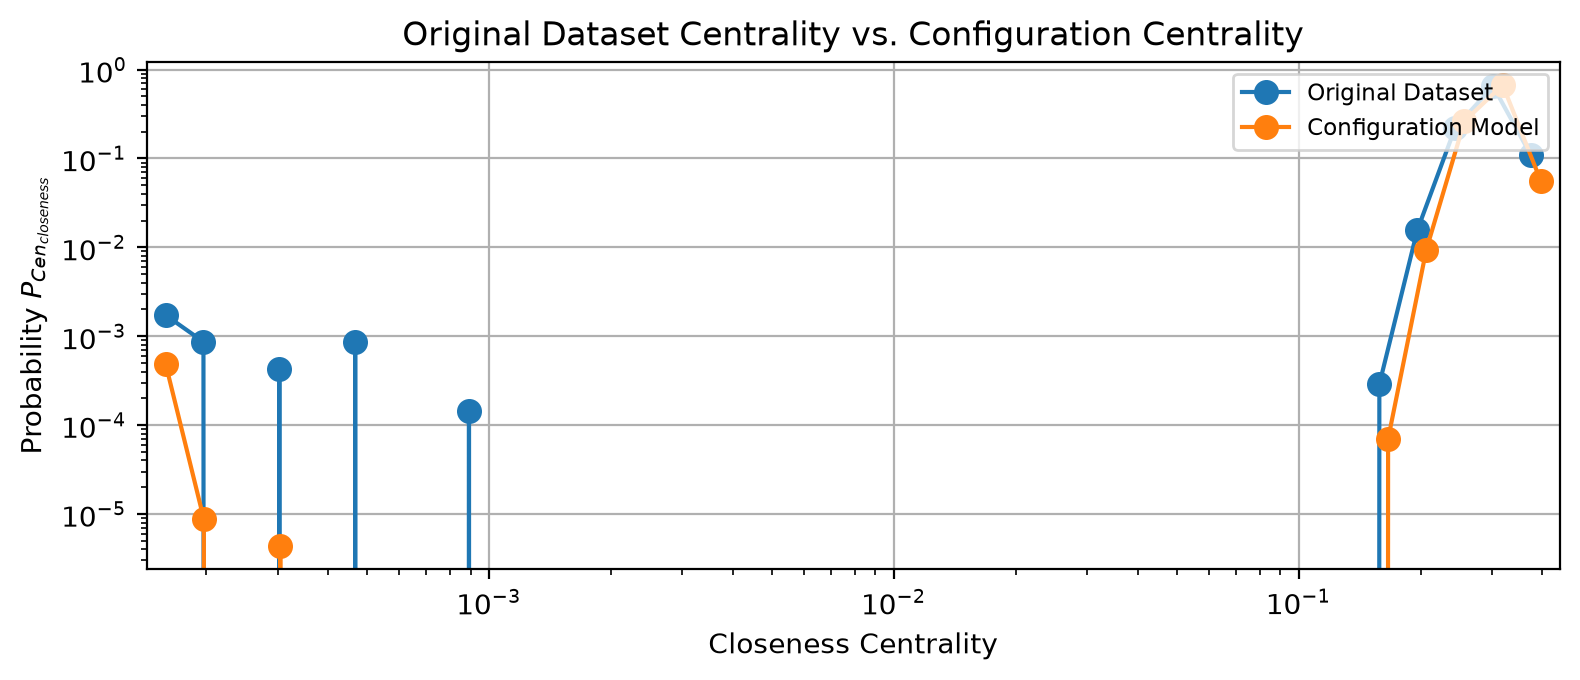

In [56]:
centrality_sequence = list(sorted_dict_c.values())
centrality_sequence_null = [v for d in closeness_centrality_nulls for v in d.values()]
#---Plotting the Centrality
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

#Finding the minimum value for log-log binning

centrality_sequence=np.asarray(centrality_sequence)
centrality_sequence_min= np.amin(centrality_sequence[centrality_sequence != np.amin(centrality_sequence)])
centrality_sequence_null=np.asarray(centrality_sequence_null)
centrality_sequence_null_min= np.amin(centrality_sequence_null[centrality_sequence_null != np.amin(centrality_sequence_null)])

num=int(2*N**(1/3))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.
bins = np.geomspace(centrality_sequence_min,np.max(centrality_sequence),num=num)
counts, bin_edges = np.histogram(centrality_sequence, bins=bins, density=False)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts/counts.sum(), marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(centrality_sequence_null_min,np.max(centrality_sequence_null),num=num)
counts_null, bin_edges_null = np.histogram(centrality_sequence_null, bins=bins_null, density=False)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null/counts_null.sum(), marker='o', ms=8, label="Configuration Model")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Original Dataset Centrality vs. Configuration Centrality")
ax.set_xlabel("Closeness Centrality")
ax.set_ylabel("Probability $P_{Cen_{closeness}}$")
true_min=min([(centrality_sequence_min), (centrality_sequence_null_min)])
true_max=max([max(centrality_sequence), max(centrality_sequence_null)])
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()

How much of this is explaine by sub-reddit and sub-reddit size? Are there really more central users here?

[0.         0.         0.03886572 ... 0.16666667 0.04166667 0.06666667]
[0.04761905 0.16666667 0.01401168 ... 0.16666667 0.         0.04444444]


/tmp/ipykernel_124333/2784620266.py:39: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(true_min,true_max)


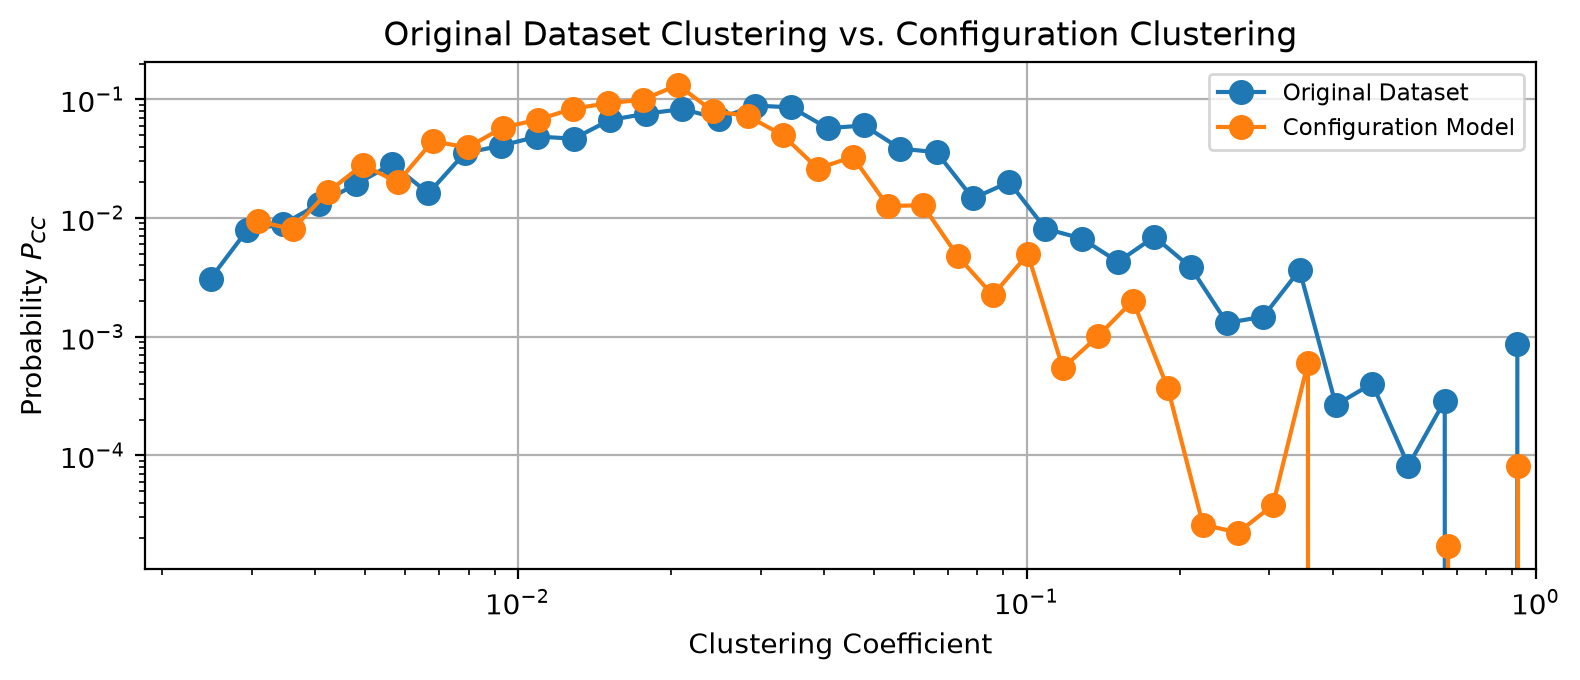

In [57]:
#---Plotting the Average Clustering Coefficient 'CC'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

#Finding the minimum value for log-log binning
cc=np.asarray(cc)
cc_min= np.amin(cc[cc != np.amin(cc)])
#PROBLEM Sampling caused clustering to either be 1 or 0. Interesting.
#cc_max= np.amax(cc[cc != np.amax(cc)])#Clustering very high so attempting to get the second largest max
cc_null=np.asarray(cc_null)
cc_null_min= np.amin(cc_null[cc_null != np.amin(cc_null)])

print(cc)
print(cc_null)

num=int(2*N**(1/3))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.

bins = np.geomspace(cc_min,np.max(cc),num=num)
counts, bin_edges = np.histogram(cc, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts/counts.sum(), marker='o', ms=8, label="Original Dataset")

bins_null = np.geomspace(cc_null_min,np.max(cc_null),num=num)
counts_null, bin_edges_null = np.histogram(cc_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null/counts_null.sum(), marker='o', ms=8, label="Configuration Model")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Original Dataset Clustering vs. Configuration Clustering")
ax.set_xlabel("Clustering Coefficient")
ax.set_ylabel("Probability $P_{CC}$")
true_min=min(min(cc), min(cc_null))
true_max=max(max(cc), max(cc_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()

Note, here due to the way I sampled and constructed the network the clustering coefficient became either a 1 or 0 in the original graph. This is because I defined each post as a component of fully-connected comments. (i.e., that comments that appear on the same post are thereby connected.)

By nature this excludes posts with no comments, and leaves us with either posts containing 1 comment, or fully connected comments should there be more than 1 on a given post.


In [88]:
import pandas as pd
#Comparing Depressed vs. Non-Depressed Nodes
G = pickle.load(open('processed/G_labeled.pkl', 'rb'))
print(G.nodes())
df = pd.DataFrame({'depressed': nx.get_node_attributes(G, 'depressed'),
                   'degree': dict(G.degree()),
                   'clustering': nx.clustering(G),
                   'n_activity': nx.get_node_attributes(G, 'n_activity')})
df = df[df['depressed'].notna()] # drop authors with no label
df.groupby('depressed')[['degree', 'clustering', 'n_activity']].median()



['janyk', 'whit7knee', 'TheAtomicPlayboy', 'farkdog', 'mastershake04', 'Olah92', 'burstaneurysm', 'high_inquisitor', 'ChickenFarmer', 'Frdl', 'Belledonner', 'Bizarro34', 'mimtarsden', 'okmkz', 'Abbernathy', 'theGodstopper', 'itswac', 'IAMnotBRAD', 'koolaid35', 'Nukleon', 'GrouchySmurf', 'BScatterplot', 'daugherk', 'serfis', 'SirLamps', 'dhanic', 'pmarsh', 'dances_w_vowels', 'ProDrug', 'The_Admin', 'Denim_cutoffs', 'NetWraythe', 'polost', 'kpsmash', 'tehsusenoh', 'RedditRedneck', 'EffinD', 'rakan959', 'atgunpoint', 'e8dingo', 'lookadistraction', 'ThatGuyWhoReddits', 'timeofnoreply', 'Ominusdarkcloud', 'sfg24', 'Koolitaliano', 'superdude4agze', 'only_death_is_real', 'AlyssaBereznak', 'Remnants', 'zionistbastard', 'Basil_Market', 'Myschyf', 'EmitStop', 'ErezYehuda', 'spartacus775', 'iProcreate', 'fishwithfeet', 'spraj', 'penis_train', 'cameronj', 'smr00', 'kmalancer', 'asdfcasdf', 'cleric04', 'ctjameson', 'ironyfree', 'pdfpdx', 'sandiegoking', 'Shelobe', 'jec68', 'tbaskerv138', 'captainba

,degree,clustering,n_activity
depressed,,,
False,11.0,0.030730,85.0
True,6.0,0.015015,41.0


['whit7knee', 'pmarsh', 'Ominusdarkcloud', 'zionistbastard', 'spartacus775', 'Shelobe', 'tbaskerv138', 'Fishtacoburrito', 'JaviMT8', 'ctwomo', 'dude____________what', 'Sgt_Pepper91', 'martijn_nl', 'moomooland', 'DuckTruck', 'Misiok', 'MileHighNugz', 'shenglong', 'drewniverse', 'sam_eats_children', 'freemeth', 'horuslives', 'arisasdf', 'volto_volte', 'Twyll', 'MultipleGodgasm', 'hillmarie', 'weirdozippers', 'GhostFaceFilla', 'dhc23', 'ohbotherjohn', 'apandafunn', 'EluciadeLuteIma', 'funkutoo', 'dirty_south', 'Frogstool', 'striptococcus', 'Telxon', 'debbiethebigdowner', 'bikenotes', 'BuddhaCat', 'Defektiv', 'Doeo', 'DraX696', 'Space-Dementia', 'Rappe', 'teh_chosen_one', 'myfirstnameisdanger', 'Andernerd', 'Waazaap', 'SquishyAndrew', 'SocietyOfDreamers', 'hrspoonie', 's8nlovesme', 'McStabYou', 'weakforce', 'asmallsparrow', 'shnoink666', 'BradimusPrime', 'sameteam', 'Themroc', 'legendaryfailure', 'TheWhiteRabbitY2K', 'PPizza', 'berda70', 'BrianSITA', 'OohLaLaa', 'luke_c', 'Colonel_Microwav

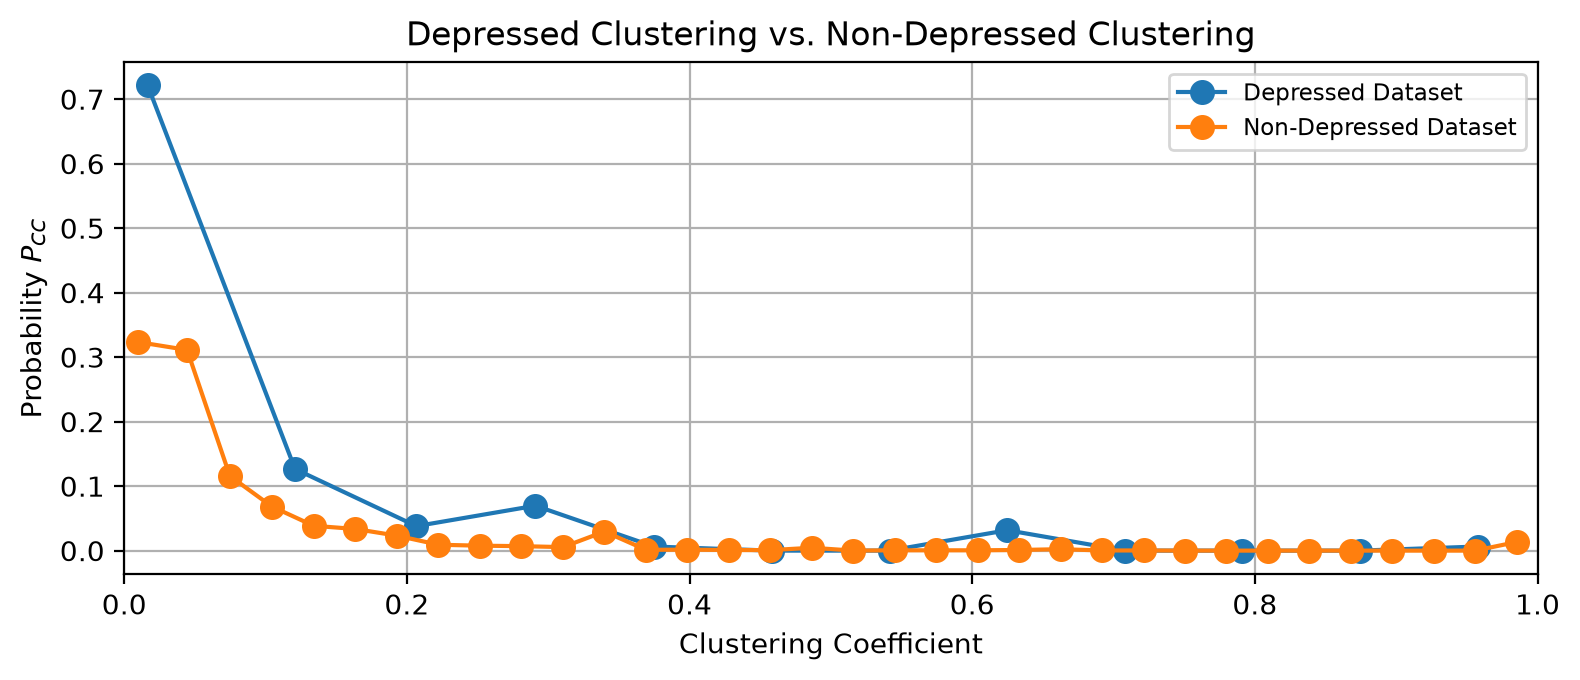

In [ ]:

#---Comparing the Clustering Coefficient 'CC'
#Starting the plotting process
fig, ax = plt.subplots(1,2,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)
depressed_subset = [
    n for n, attr in G.nodes(data=True)
    if attr.get('depressed') is True
]
non_depressed_subset = [
    n for n, attr in G.nodes(data=True)
    if attr.get('depressed') is False
]
print(depressed_subset)
print(non_depressed_subset)

cc = list(dict(nx.clustering(G,nodes=depressed_subset)).values())
cc_null = list(dict(nx.clustering(G,nodes=non_depressed_subset)).values())
#Finding the minimum value for log-log binning
cc=np.asarray(cc)
cc_min= np.amin(cc[cc != np.amin(cc)])
cc_null=np.asarray(cc_null)
cc_null_min= np.amin(cc_null[cc_null != np.amin(cc_null)])

num=int(2*len(depressed_subset)**(1/3))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.
bins = np.linspace(cc_min,np.max(cc),num=num)
counts, bin_edges = np.histogram(cc, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax[0].plot(bin_centers, counts/counts.sum(), marker='o', ms=8, label="Depressed Dataset")

num_n=int(2*len(non_depressed_subset)**(1/3))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.
bins_null = np.linspace(cc_null_min,np.max(cc_null),num=num_n)
counts_null, bin_edges_null = np.histogram(cc_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax[0].plot(bin_centers_null, counts_null/counts_null.sum(), marker='o', ms=8, label="Non-Depressed Dataset")

#Specifying figure details below:
#ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax[0].legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax[0].set_title("Depressed Clustering vs. Non-Depressed Clustering")
ax[0].set_xlabel("Clustering Coefficient")
ax[0].set_ylabel("Probability $P_{CC}$")
true_min=min(min(cc), min(cc_null))
true_max=max(max(cc), max(cc_null))
ax[0].set_xlim(true_min,true_max)
ax[0].grid(True)
plt.tight_layout()
plt.show()
#------------------------------Comparison to log-log---------------------------------------------------------------
num=int(2*len(depressed_subset)**(1/3))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.
bins = np.geomspace(cc_min,np.max(cc),num=num)
counts, bin_edges = np.histogram(cc, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax[0].loglog(bin_centers, counts/counts.sum(), marker='o', ms=8, label="Depressed Dataset")

num_n=int(2*len(non_depressed_subset)**(1/3))#Rubia, José Moral De La. “Rice University Rule to Determine the Number of Bins.” Open Journal of Statistics 14, no. 01 (2024): 119–49. https://doi.org/10.4236/ojs.2024.141006.
bins_null = np.geomspace(cc_null_min,np.max(cc_null),num=num_n)
counts_null, bin_edges_null = np.histogram(cc_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax[0].loglog(bin_centers_null, counts_null/counts_null.sum(), marker='o', ms=8, label="Non-Depressed Dataset")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax[0].legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax[0].set_title("Depressed Clustering vs. Non-Depressed Clustering")
ax[0].set_xlabel("Clustering Coefficient")
ax[0].set_ylabel("Probability $P_{CC}$")
true_min=min(min(cc), min(cc_null))
true_max=max(max(cc), max(cc_null))
ax[0].set_xlim(true_min,true_max)
ax[0].grid(True)
plt.tight_layout()
plt.show()


Here we can see Depressed users were ever so slightly higher clustering and lower comment counts, however the difference appear to be relatively marginal.
Interestingly though we do see that it is far more likely for depressed users to be isolate, i.e., 0 clustering. In fact this value is nearly double.

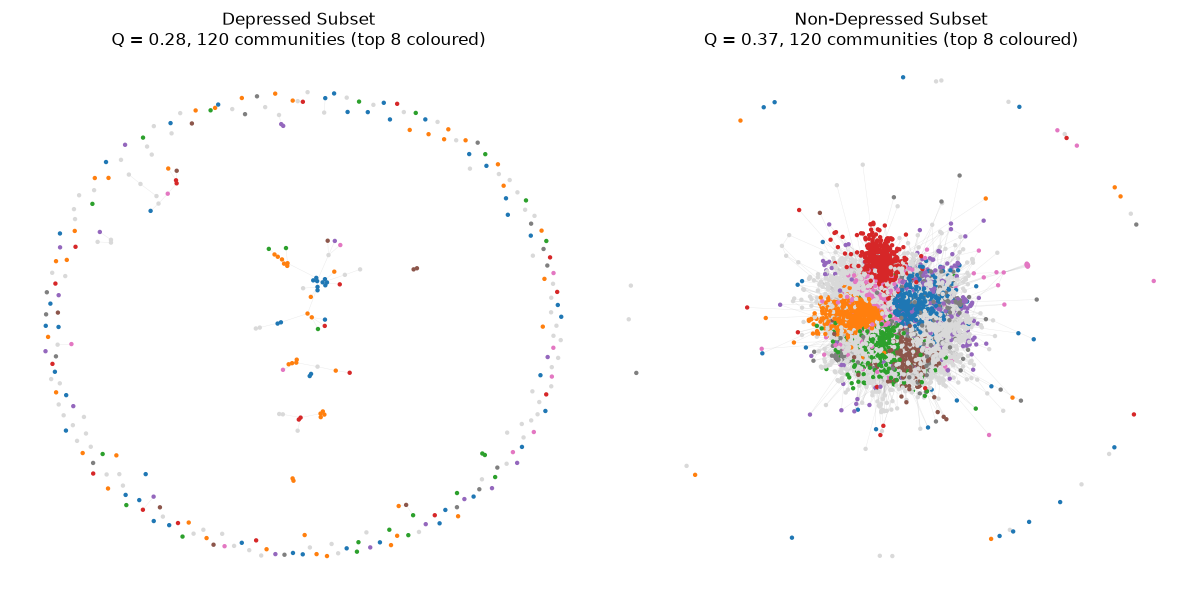

In [108]:
#Community Visualization of Depressed Users
from collections import Counter

top_k = 8 # number of largest communities to give their own colour
palette = plt.cm.tab10(np.arange(top_k))
grey = (0.85, 0.85, 0.85, 1.0)

def community_color(comm, biggest):
    # Colour for a community: its own colour if it's one of the biggest, grey otherwise
    if comm in biggest:
        return palette[biggest.index(comm)]
    return grey

def plot_communities(graph, partition, ax, title):
    # Only draw the giant component so the ring of tiny components doesn't clutter the plot
    giant = graph.copy()

    # Layout-only weights: edges inside a community pull hard, edges between communities pull weakly.
    # This lets the spring layout separate the communities visually (it doesn't change the graph itself)
    for u, v in giant.edges():
        if partition[u] == partition[v]:
            giant[u][v]['layout_weight'] = 1.0
        else:
            giant[u][v]['layout_weight'] = 0.05
    pos = nx.spring_layout(giant, seed=42, weight='layout_weight', iterations=100) # each graph gets its OWN layout

    biggest = [comm for comm, size in Counter(partition.values()).most_common(top_k)]
    node_colors = [community_color(partition[node], biggest) for node in giant.nodes()]

    nx.draw_networkx_edges(giant, pos, ax=ax, edge_color='.7', width=0.3, alpha=0.3)
    nx.draw_networkx_nodes(giant, pos, ax=ax, node_size=10, node_color=node_colors, linewidths=0)

    Q = community.modularity(partition, graph)
    n_comms = len(set(partition.values()))
    ax.set_title(f"{title}\nQ = {Q:.2f}, {n_comms} communities (top {top_k} coloured)")
    ax.axis('off')

G_dep= nx.induced_subgraph(G,depressed_subset)
G_non_dep= nx.induced_subgraph(G,non_depressed_subset)


fig, ax = plt.subplots(1,2,figsize=(12,6),dpi=100)

plot_communities(G_dep, partition, ax[0], "Depressed Subset")
plot_communities(G_non_dep, partition, ax[1], "Non-Depressed Subset")
plt.tight_layout()
plt.show()